# Particle Size Distribution, Crusher Efficiency, Dissolution & Bioavailability
**FMO Mini Project (24BTEN2031) – simulated data analysis**

This notebook covers the Simulation topic *PSD and Efficiency of Different Crushers* and links it to the case study *PSD's Role in Drug Dissolution and Bioavailability*.

| Step | What it does |
|---|---|
| 1 | Product PSD of 5 size-reduction machines (Rosin-Rammler model), D10/D50/D90, span, Sauter diameter |
| 2 | Energy laws: Kick, Rittinger, Bond |
| 3 | Crusher efficiency (Bond and surface-energy based) |
| 4 | Simulated sieve analysis and Rosin-Rammler fit |
| 5 | Figures 1–6: PSD, energy, efficiency, sieve, surface area |
| 6 | Dissolution (Noyes-Whitney, shrinking spheres) and one-compartment PK |
| 7 | Figures 7–8, summary table and Excel export |

> **All data are simulated** from textbook models with assumed, illustrative parameters. They are not experimental results.



In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
OUT = os.getcwd()
FIG = os.path.join(OUT, "figures")
os.makedirs(FIG, exist_ok=True)

COL = {"Jaw crusher": "#0072B2", "Roll crusher": "#E69F00", "Hammer mill": "#009E73",
       "Ball mill": "#CC79A7", "Jet (fluid-energy) mill": "#D55E00"}
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
                     "axes.titleweight": "bold", "legend.frameon": False})

## Assumptions
Material properties, feed size, and the five machines (Rosin-Rammler size modulus d′, spread n, and an assumed actual specific energy). Change these values to explore other scenarios.

In [ ]:
RHO = 1400.0
WI = 8.0
GAMMA = 1.0
F80 = 20_000.0
FEED_TOP = 25_000.0
MACH = {
    "Jaw crusher":            dict(dprime=8000.0, n=1.4, E=1.0),
    "Roll crusher":           dict(dprime=2000.0, n=1.8, E=2.5),
    "Hammer mill":            dict(dprime=300.0,  n=1.2, E=6.0),
    "Ball mill":              dict(dprime=40.0,   n=1.1, E=25.0),
    "Jet (fluid-energy) mill": dict(dprime=6.0,   n=1.8, E=120.0),
}
NAMES = list(MACH)

edges = np.logspace(-1, np.log10(FEED_TOP), 301)
dmid = np.sqrt(edges[:-1] * edges[1:])

def rr_cdf(d, dp, n):
    return 1.0 - np.exp(-(d / dp) ** n)

def bins_from_cdf(cdf):
    w = np.diff(cdf(edges))
    return w / w.sum()

def pct(d, F, p):
    return float(np.exp(np.interp(p, F, np.log(d))))

## Simulation 1 – Product PSD of each crusher
Rosin-Rammler cumulative distribution F(d) = 1 − exp[−(d/d′)ⁿ]. From the binned distribution we compute D10, D50, D80, D90, span = (D90−D10)/D50, Sauter mean d32 = 1/Σ(wᵢ/dᵢ) and specific surface S = 6/(ρ·d32).

In [ ]:
rows, W = [], {}
for m, p in MACH.items():
    w = bins_from_cdf(lambda d: rr_cdf(d, p["dprime"], p["n"]))
    W[m] = w
    F = np.cumsum(w)
    d10, d50, d80, d90 = (pct(dmid, F, q) for q in (.10, .50, .80, .90))
    d32 = 1.0 / np.sum(w / dmid)
    dmean = np.sum(w * dmid)
    S = 6.0 / (RHO * d32 * 1e-6)
    rows.append(dict(Machine=m, d_prime_um=p["dprime"], n=p["n"], D10_um=d10, D50_um=d50,
                     D80_um=d80, D90_um=d90, Span=(d90 - d10) / d50, Sauter_d32_um=d32,
                     Mass_mean_um=dmean, Specific_surface_m2_per_kg=S))
sim1 = pd.DataFrame(rows).set_index("Machine")

## Simulation 2 – Energy laws
Kick: E = K ln(F/P). Rittinger: E = K(1/P − 1/F). Bond: E = 10·Wi(1/√P − 1/√F). The Kick and Rittinger constants are calibrated so that all three agree with Bond at P80 = 100 µm.

In [ ]:
def bond(P, F=F80):
    return 10 * WI * (1 / np.sqrt(P) - 1 / np.sqrt(F))
P_cal = 100.0
Kk = bond(P_cal) / np.log(F80 / P_cal)
Kr = bond(P_cal) / (1 / P_cal - 1 / F80)
Pgrid = np.logspace(0, np.log10(F80 * 0.95), 300)
laws = pd.DataFrame({"P80_um": Pgrid,
                     "Kick_kWh_t": Kk * np.log(F80 / Pgrid),
                     "Rittinger_kWh_t": Kr * (1 / Pgrid - 1 / F80),
                     "Bond_kWh_t": bond(Pgrid)})

## Simulation 3 – Crusher efficiency
- **Bond efficiency** = ideal Bond energy / assumed actual energy.
- **Surface-energy efficiency** = (new surface × surface energy) / actual energy.
- Also the new surface area created per kWh.

In [ ]:
S_feed = 6.0 / (RHO * (1.0 / np.sum(bins_from_cdf(lambda d: rr_cdf(d, 12000., 1.5)) / dmid)) * 1e-6)
rows = []
for m, p in MACH.items():
    P80 = pct(dmid, np.cumsum(W[m]), 0.8)
    S = sim1.loc[m, "Specific_surface_m2_per_kg"]
    dS = S - S_feed
    E_surf = dS * GAMMA / 3.6e6 * 1000
    E_bond = bond(P80)
    rows.append(dict(Machine=m, F80_um=F80, P80_um=P80, Reduction_ratio=F80 / P80,
                     Actual_energy_kWh_t=p["E"], Bond_energy_kWh_t=E_bond,
                     Bond_efficiency_pct=100 * E_bond / p["E"],
                     New_surface_m2_per_kg=dS,
                     Surface_energy_efficiency_pct=100 * E_surf / p["E"],
                     New_surface_per_kWh_m2=dS * 1000 / p["E"]))
sim3 = pd.DataFrame(rows).set_index("Machine")

## Simulation 4 – Sieve analysis
A 1 kg sample is 'sieved' through a standard stack (16 mm to 25 µm plus pan) with 2 % random measurement noise. A Rosin-Rammler plot, ln[ln(1/(1−F))] vs ln d, recovers d′ and n. Products finer than the finest sieve cannot be characterised (the jet-mill product falls entirely in the pan), so laser diffraction would be needed.

In [ ]:
sieves = np.array([16000, 8000, 4000, 2000, 1000, 500, 250, 125, 63, 45, 25, 0], float)
def sieve_table(m, sample_g=1000.0):
    pf = rr_cdf(sieves[:-1], MACH[m]["dprime"], MACH[m]["n"])
    ret = np.empty(len(sieves))
    ret[0] = 1 - pf[0]
    ret[1:-1] = pf[:-1] - pf[1:]
    ret[-1] = pf[-1]
    ret = ret * rng.normal(1, 0.02, len(ret)); ret = np.clip(ret, 0, None); ret /= ret.sum()
    g = ret * sample_g
    cum_pass = 100 * (1 - np.cumsum(ret))
    return pd.DataFrame({"Sieve_aperture_um": sieves, "Mass_retained_g": g,
                         "Mass_fraction": ret, "Cum_pass_pct": cum_pass})
sieve_tabs = {m: sieve_table(m) for m in NAMES}

def sieve_stats(tab):
    ap = tab["Sieve_aperture_um"].values; x = tab["Mass_fraction"].values
    lower = ap
    upper = np.append(np.inf, ap[:-1])
    dm = np.where(np.isinf(upper), lower * 1.5, np.where(lower == 0, upper / 2, np.sqrt(upper * lower)))
    d32 = 1 / np.sum(x / dm)
    return d32, np.sum(x * dm)

rr_fit, sieve_cmp = {}, []
for m, t in sieve_tabs.items():
    sub = t[(t.Sieve_aperture_um > 0) & (t.Cum_pass_pct > 1) & (t.Cum_pass_pct < 99)]
    if len(sub) >= 3:
        x = np.log(sub.Sieve_aperture_um.values)
        y = np.log(-np.log(1 - sub.Cum_pass_pct.values / 100))
        n_fit, c = np.polyfit(x, y, 1); dp_fit = np.exp(-c / n_fit)
    else:
        n_fit = dp_fit = np.nan
    rr_fit[m] = (dp_fit, n_fit)
    d32s, _ = sieve_stats(t)
    pan = 100 * t.Mass_fraction.iloc[-1]
    sieve_cmp.append(dict(Machine=m, True_d_prime_um=MACH[m]["dprime"], Fitted_d_prime_um=dp_fit,
                          True_n=MACH[m]["n"], Fitted_n=n_fit, Points_in_fit=len(sub),
                          Pan_pct=pan, Sauter_from_sieves_um=d32s,
                          True_Sauter_um=sim1.loc[m, "Sauter_d32_um"],
                          Error_pct=100 * (d32s - sim1.loc[m, "Sauter_d32_um"]) / sim1.loc[m, "Sauter_d32_um"]))
sim4 = pd.DataFrame(sieve_cmp).set_index("Machine")

## Simulation 6 – Surface area vs particle size
Specific surface of spheres, S = 6/(ρd), so S ∝ 1/d.

In [ ]:
d_s = np.logspace(-1, 4, 200)
S_s = 6 / (RHO * d_s * 1e-6)

## Simulations 7 and 8 – Dissolution and bioavailability
Each size bin is a population of spheres that shrink by Noyes-Whitney dissolution, dr/dt = −D(Cs − C)/(ρ·h) with h = min(r, 30 µm). Undissolved solid and dissolved drug leave the GI tract with first-order transit (mean 4 h); dissolved drug is absorbed (ka) into a one-compartment body (ke, Vd). Cmax, Tmax, AUC and relative bioavailability are computed.

Only the hammer, ball and jet mill products are used as powders (jaw and roll crushers give mm-sized lumps). Four micronisation grades of the same drug (log-normal, σg = 2) are also compared.

In [ ]:
DOSE = 100e-6
V = 250e-6
CS = 0.10
D = 7e-10
HMAX = 30e-6
KT = 1 / (4 * 3600.0)
KA = 2.0 / 3600.0
KE = 0.2 / 3600.0
VD = 50e-3

def simulate(w, t_end_h=12.0, dt=0.25):
    r = dmid * 0.5e-6
    mass_bin = w * DOSE
    N0 = mass_bin / (RHO * 4 / 3 * np.pi * r ** 3)
    r_t = r.copy()
    steps = int(t_end_h * 3600 / dt)
    rec = max(1, int(60 / dt))
    A_gi = 0.0; A_c = 0.0
    out = []
    for k in range(steps + 1):
        t = k * dt
        f = np.exp(-KT * t)
        N = N0 * f
        if k % rec == 0:
            solid = np.sum(N * RHO * 4 / 3 * np.pi * r_t ** 3)
            out.append((t / 3600, A_gi / V * 1e3, A_c / VD * 1e3, solid * 1e6, A_gi * 1e6, A_c * 1e6))
        C = A_gi / V
        kap = D * max(CS - C, 0.0) / RHO
        small = r_t <= HMAX
        r2 = np.where(small, np.maximum(r_t ** 2 - 2 * kap * dt, 0.0), 0)
        r_new = np.where(small, np.sqrt(r2), np.maximum(r_t - kap * dt / HMAX, 0.0))
        rate = np.sum(N * RHO * 4 / 3 * np.pi * (r_t ** 3 - r_new ** 3)) / dt
        r_t = r_new
        dA_gi = rate - KA * A_gi - KT * A_gi
        dA_c = KA * A_gi - KE * A_c
        A_gi += dA_gi * dt; A_c += dA_c * dt
    df = pd.DataFrame(out, columns=["t_h", "C_gi_mg_per_mL", "Cp_ug_per_mL", "Solid_left_mg",
                                    "Dissolved_in_GI_mg", "Amount_in_body_mg"])
    return df

def pk_metrics(df):
    t = df.t_h.values; cp = df.Cp_ug_per_mL.values
    auc = np.trapezoid(cp, t)

    return dict(Cmax_ug_per_mL=cp.max(), Tmax_h=t[cp.argmax()], AUC0_12_ug_h_per_mL=auc)


DISS = {m: simulate(W[m]) for m in ["Hammer mill", "Ball mill", "Jet (fluid-energy) mill"]}


grades = {"Coarse (D50 100 um)": 100.0, "Medium (D50 30 um)": 30.0,
          "Fine (D50 10 um)": 10.0, "Micronised (D50 3 um)": 3.0}
GW = {}
for g, d50 in grades.items():
    cdf = lambda d, d50=d50: 0.5 * (1 + np.vectorize(__import__("math").erf)(np.log(d / d50) / (np.log(2.0) * np.sqrt(2))))
    GW[g] = bins_from_cdf(cdf)
GRD = {g: simulate(w) for g, w in GW.items()}
GCOL = {"Coarse (D50 100 um)": "#0072B2", "Medium (D50 30 um)": "#E69F00",
        "Fine (D50 10 um)": "#009E73", "Micronised (D50 3 um)": "#D55E00"}

def fraction_absorbed(df):
    t = df.t_h.values * 3600
    return 100 * np.trapezoid(KA * df.Dissolved_in_GI_mg.values * 1e-6, t) / DOSE

def pct_diss(df, th):
    i = (df.t_h - th).abs().idxmin()
    f = np.exp(-KT * th * 3600)
    return 100 * (1 - df.Solid_left_mg[i] / (100 * f))

rows = []
for name, d in {**DISS, **GRD}.items():
    mtr = pk_metrics(d)
    rows.append(dict(Powder=name, Pct_of_dose_dissolved_30min=pct_diss(d, 0.5),
                     Pct_of_dose_dissolved_1h=pct_diss(d, 1.0), Pct_of_dose_dissolved_2h=pct_diss(d, 2.0),
                     Fraction_absorbed_pct=fraction_absorbed(d), Cmax_ug_per_mL=mtr["Cmax_ug_per_mL"],
                     Tmax_h=mtr["Tmax_h"], AUC0_12_ug_h_per_mL=mtr["AUC0_12_ug_h_per_mL"]))
sim78 = pd.DataFrame(rows).set_index("Powder")
sim78["Relative_bioavailability_vs_Micronised_pct"] = 100 * sim78.AUC0_12_ug_h_per_mL / sim78.loc["Micronised (D50 3 um)", "AUC0_12_ug_h_per_mL"]

## Figures
Each figure is shown here and saved in the `figures/` folder.

In [ ]:
def save(fig, name):
    fig.tight_layout(); fig.savefig(os.path.join(FIG, name), dpi=170); plt.show()

### Figure 1 – PSD curves of the five machines

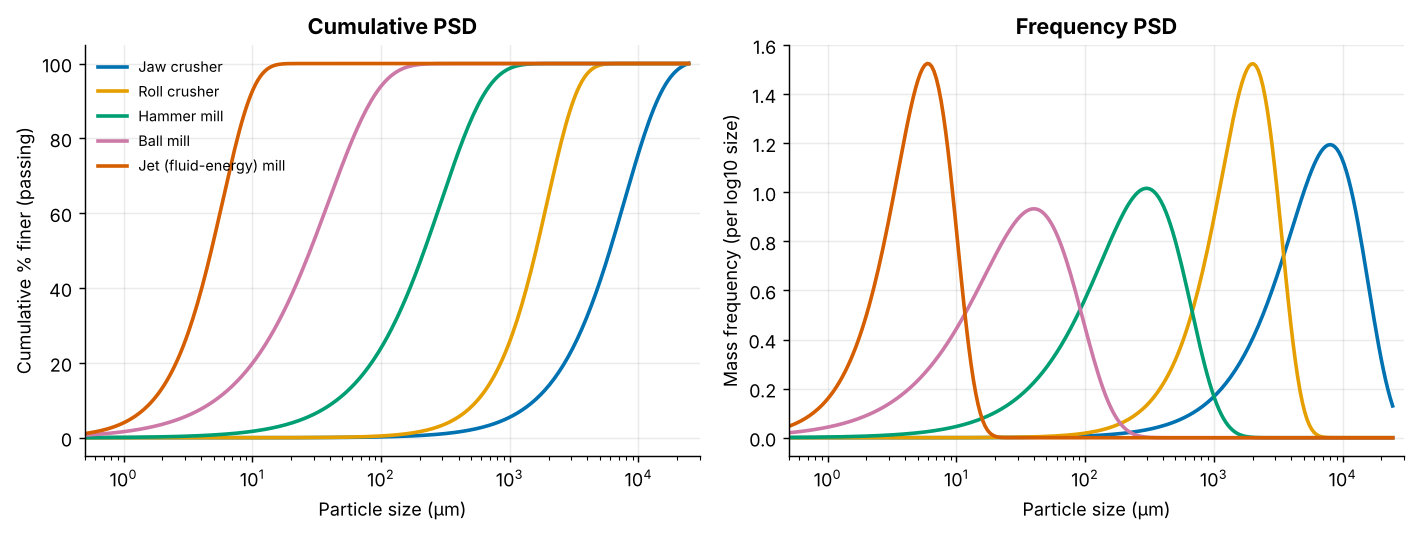

In [ ]:
# Fig 1: PSD curves
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for m in NAMES:
    ax[0].plot(dmid, 100 * np.cumsum(W[m]), color=COL[m], lw=2, label=m)
    ax[1].plot(dmid, W[m] / np.diff(np.log10(edges)), color=COL[m], lw=2, label=m)
for a, yl, ti in zip(ax, ["Cumulative % finer (passing)", "Mass frequency (per log10 size)"],
                     ["Cumulative PSD", "Frequency PSD"]):
    a.set_xscale("log"); a.set_xlabel("Particle size (µm)"); a.set_ylabel(yl); a.set_title(ti)
    a.set_xlim(0.5, 3e4)
ax[0].legend(loc="upper left", fontsize=8)
save(fig, "fig1_PSD_of_crushers.png")

### Figure 2 – D10 / D50 / D90 and span

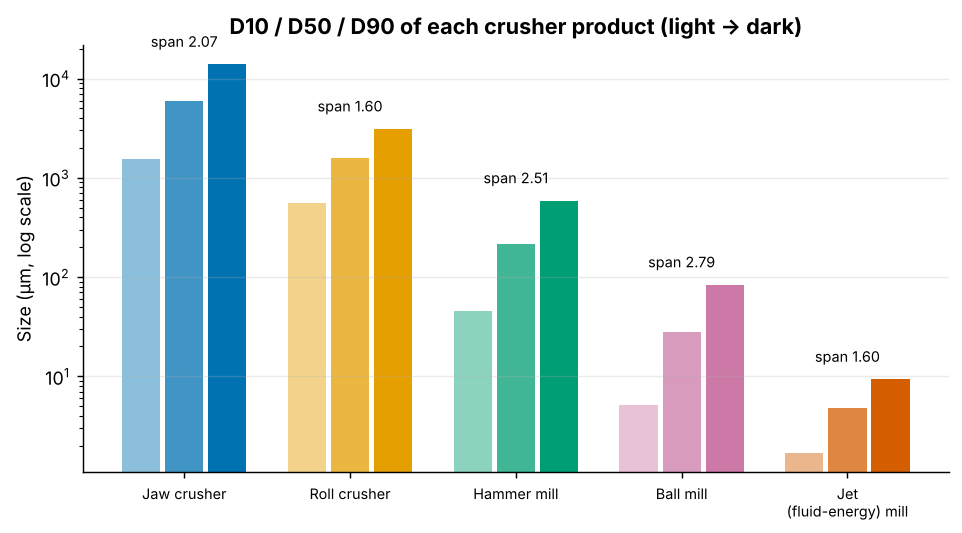

In [ ]:
# Fig 2: D10/D50/D90 + span
fig, ax = plt.subplots(figsize=(7.5, 4.2))
x = np.arange(len(NAMES)); bw = 0.26
for i, (c, lab, al) in enumerate([("D10_um", "D10", .45), ("D50_um", "D50", .75), ("D90_um", "D90", 1.0)]):
    ax.bar(x + (i - 1) * bw, sim1[c].values, bw - 0.03, color=[COL[m] for m in NAMES], alpha=al)
ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels([n.replace(" (", "\n(") for n in NAMES], fontsize=8)
ax.set_ylabel("Size (µm, log scale)"); ax.set_title("D10 / D50 / D90 of each crusher product (light → dark)")
for xi, m in zip(x, NAMES):
    ax.text(xi, sim1.loc[m, "D90_um"] * 1.5, f"span {sim1.loc[m, 'Span']:.2f}", ha="center", fontsize=8)
ax.grid(axis="x", alpha=0)
save(fig, "fig2_D10_D50_D90_span.png")

### Figure 3 – Energy laws vs actual machine energy

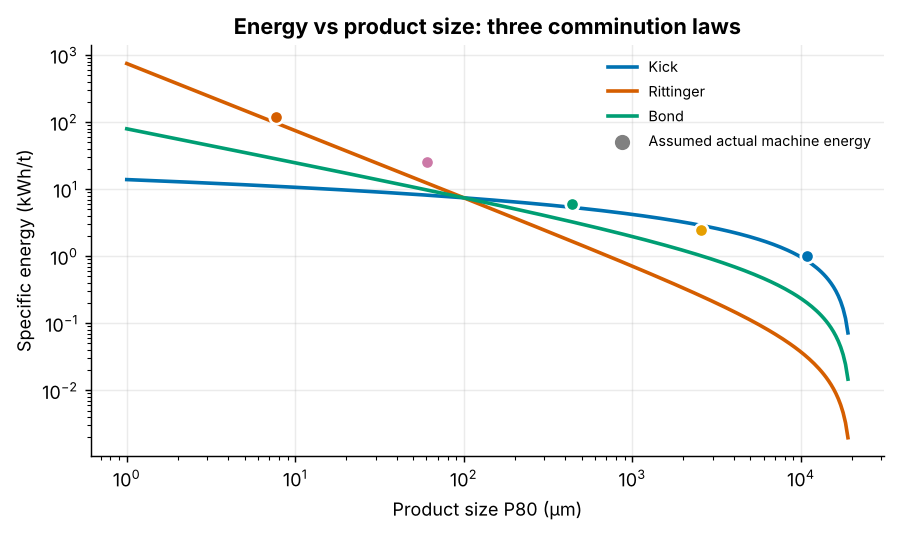

In [ ]:
# Fig 3: energy laws
fig, ax = plt.subplots(figsize=(7, 4.2))
for c, lab, col, ls in [("Kick_kWh_t", "Kick", "#0072B2", "-"), ("Rittinger_kWh_t", "Rittinger", "#D55E00", "-"),
                        ("Bond_kWh_t", "Bond", "#009E73", "-")]:
    ax.plot(laws.P80_um, laws[c], color=col, lw=2, ls=ls, label=lab)
for m in NAMES:
    ax.scatter(sim3.loc[m, "P80_um"], sim3.loc[m, "Actual_energy_kWh_t"], color=COL[m], s=55, zorder=5,
               edgecolor="white", linewidth=1.5)
ax.scatter([], [], color="grey", s=55, label="Assumed actual machine energy")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Product size P80 (µm)")
ax.set_ylabel("Specific energy (kWh/t)"); ax.set_title("Energy vs product size: three comminution laws")
ax.legend(fontsize=8)
save(fig, "fig3_energy_laws.png")

### Figure 4 – Crusher efficiency

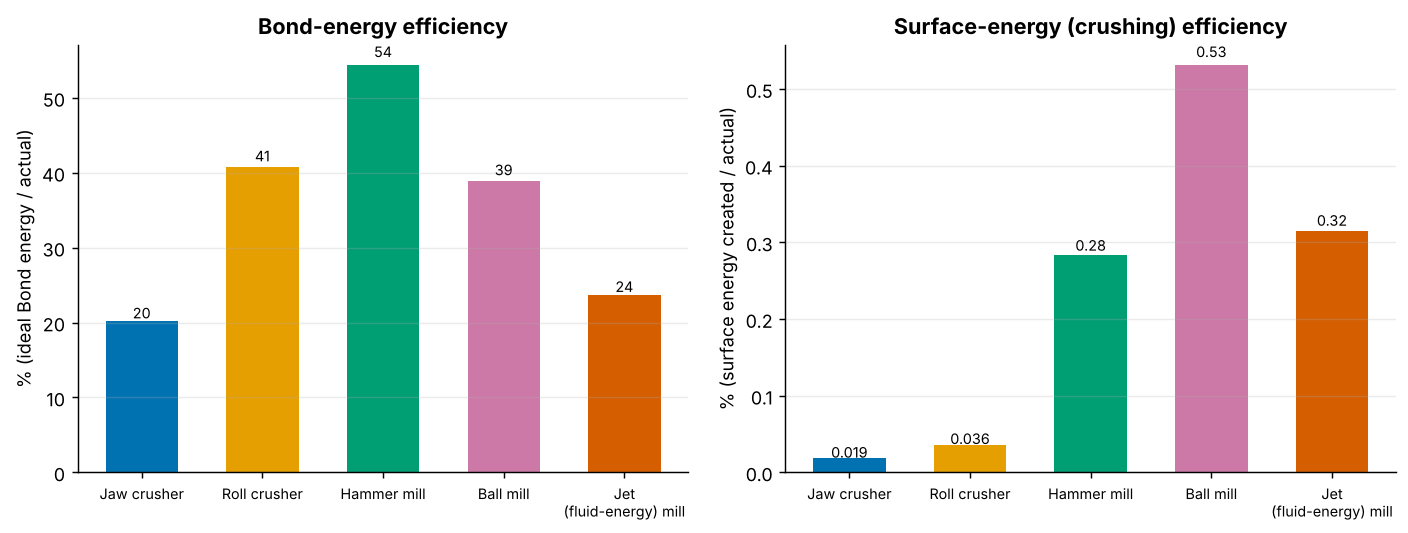

In [ ]:
# Fig 4: efficiency
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, c, t, yl in [(ax[0], "Bond_efficiency_pct", "Bond-energy efficiency", "% (ideal Bond energy / actual)"),
                    (ax[1], "Surface_energy_efficiency_pct", "Surface-energy (crushing) efficiency", "% (surface energy created / actual)")]:
    v = sim3[c].values
    a.bar(range(len(NAMES)), v, color=[COL[m] for m in NAMES], width=0.6)
    a.set_xticks(range(len(NAMES))); a.set_xticklabels([n.replace(" (", "\n(") for n in NAMES], fontsize=8)
    a.set_title(t); a.set_ylabel(yl); a.grid(axis="x", alpha=0)
    for i, val in enumerate(v):
        a.text(i, val * 1.02, f"{val:.2g}", ha="center", fontsize=8)
save(fig, "fig4_crusher_efficiency.png")

### Figure 5 – Sieve analysis and Rosin-Rammler fit

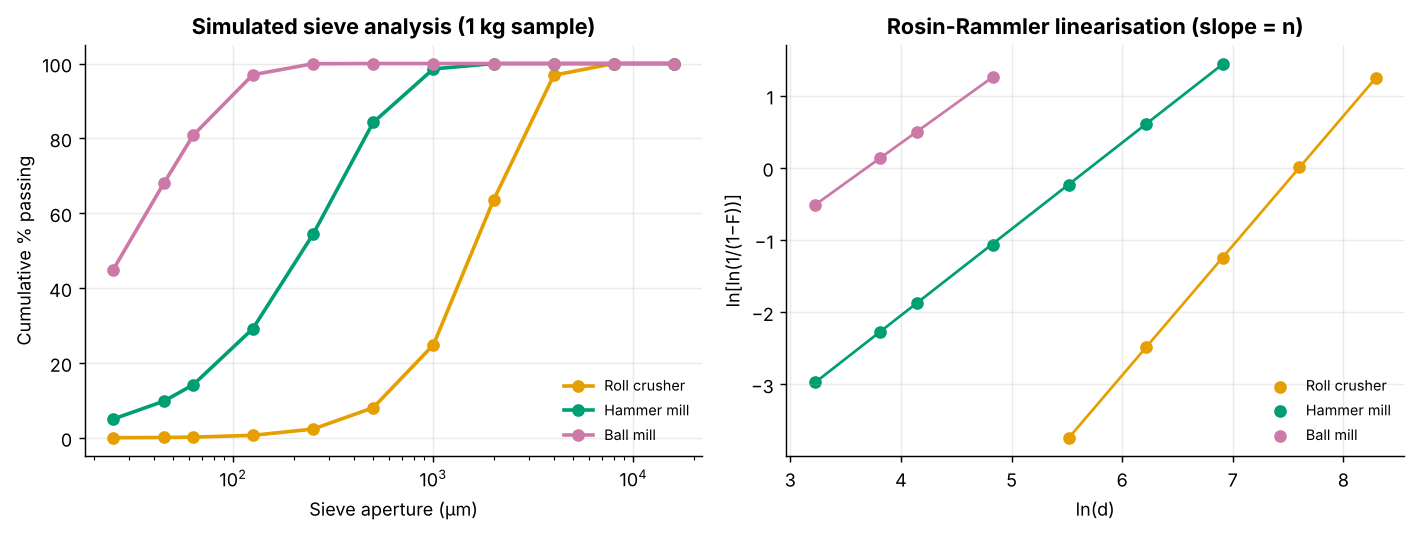

In [ ]:
# Fig 5: sieve analysis hammer & ball + RR plot
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for m in ["Roll crusher", "Hammer mill", "Ball mill"]:
    t = sieve_tabs[m]; tt = t[t.Sieve_aperture_um > 0]
    ax[0].plot(tt.Sieve_aperture_um, tt.Cum_pass_pct, "o-", color=COL[m], lw=2, label=m)
    sub = tt[(tt.Cum_pass_pct > 1) & (tt.Cum_pass_pct < 99)]
    if len(sub) >= 3:
        ax[1].scatter(np.log(sub.Sieve_aperture_um), np.log(-np.log(1 - sub.Cum_pass_pct / 100)), color=COL[m], label=m)
        dp, n = rr_fit[m]; xx = np.linspace(np.log(sub.Sieve_aperture_um.min()), np.log(sub.Sieve_aperture_um.max()), 20)
        ax[1].plot(xx, n * (xx - np.log(dp)), color=COL[m], lw=1.5)
ax[0].set_xscale("log"); ax[0].set_xlabel("Sieve aperture (µm)"); ax[0].set_ylabel("Cumulative % passing")
ax[0].set_title("Simulated sieve analysis (1 kg sample)"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("ln(d)"); ax[1].set_ylabel("ln[ln(1/(1−F))]"); ax[1].set_title("Rosin-Rammler linearisation (slope = n)")
ax[1].legend(fontsize=8)
save(fig, "fig5_sieve_analysis.png")

### Figure 6 – Surface area vs particle size

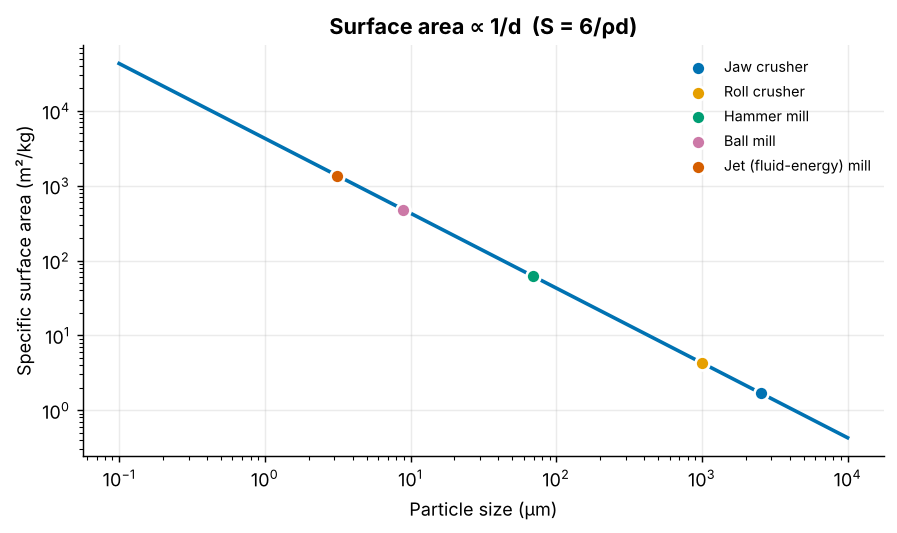

In [ ]:
# Fig 6: surface area vs size
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(d_s, S_s, color="#0072B2", lw=2)
for m in NAMES:
    ax.scatter(sim1.loc[m, "Sauter_d32_um"], sim1.loc[m, "Specific_surface_m2_per_kg"], color=COL[m], s=60,
               zorder=5, edgecolor="white", linewidth=1.5, label=m)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Particle size (µm)")
ax.set_ylabel("Specific surface area (m²/kg)"); ax.set_title("Surface area ∝ 1/d  (S = 6/ρd)")
ax.legend(fontsize=8)
save(fig, "fig6_surface_area_vs_size.png")

### Figure 7 – Dissolution profiles

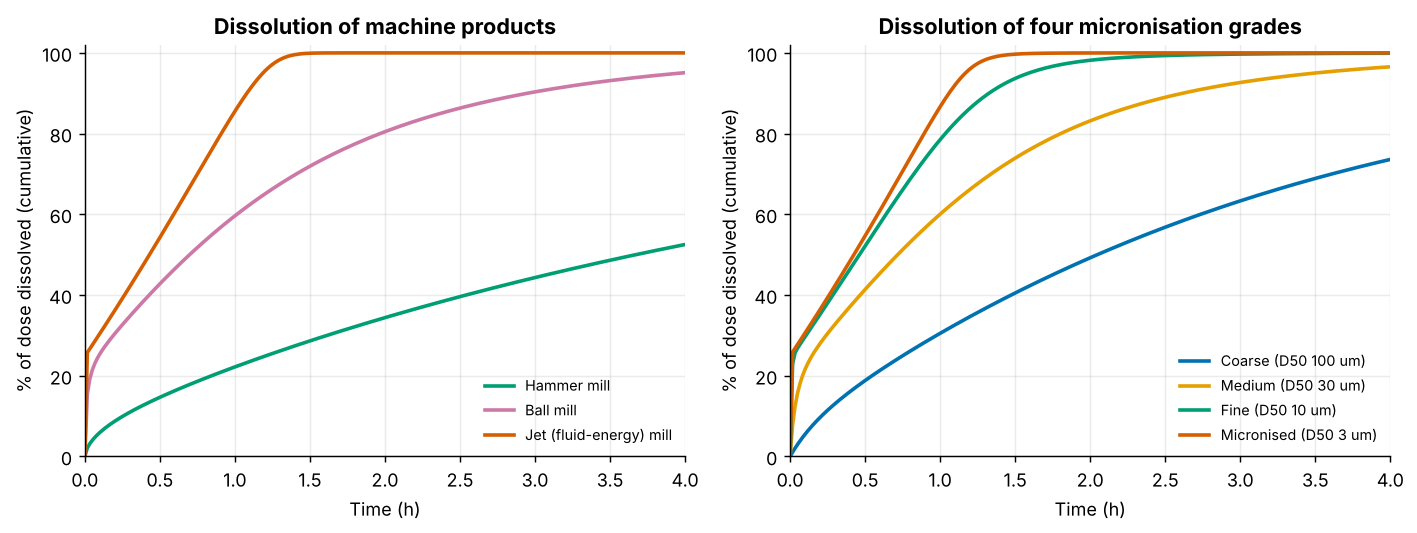

In [ ]:
# Fig 7: dissolution
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for m, d in DISS.items():
    f = np.exp(-KT * d.t_h * 3600)
    ax[0].plot(d.t_h, 100 * (1 - d.Solid_left_mg / (100 * f)), color=COL[m], lw=2, label=m)
for g, d in GRD.items():
    f = np.exp(-KT * d.t_h * 3600)
    ax[1].plot(d.t_h, 100 * (1 - d.Solid_left_mg / (100 * f)), color=GCOL[g], lw=2, label=g)
for a, t in zip(ax, ["Dissolution of machine products", "Dissolution of four micronisation grades"]):
    a.set_xlim(0, 4); a.set_ylim(0, 102); a.set_xlabel("Time (h)"); a.set_ylabel("% of dose dissolved (cumulative)")
    a.set_title(t); a.legend(fontsize=8)
save(fig, "fig7_dissolution_profiles.png")

### Figure 8 – Plasma concentration profiles

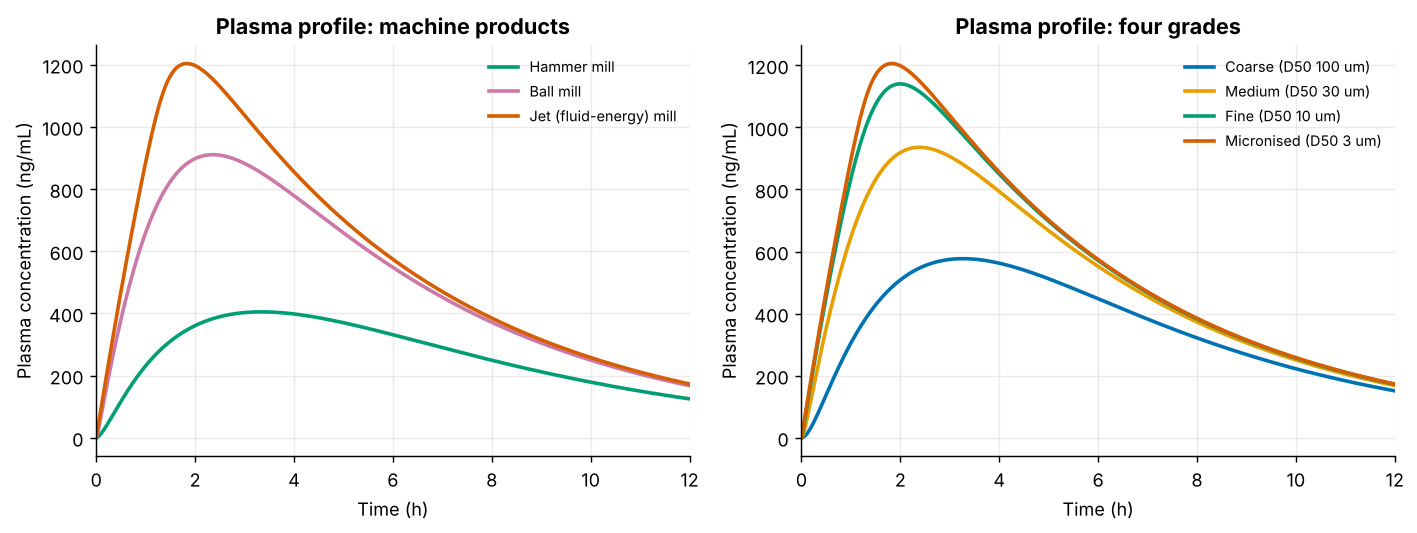

In [ ]:
# Fig 8: plasma curves
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for m, d in DISS.items():
    ax[0].plot(d.t_h, d.Cp_ug_per_mL * 1000, color=COL[m], lw=2, label=m)
for g, d in GRD.items():
    ax[1].plot(d.t_h, d.Cp_ug_per_mL * 1000, color=GCOL[g], lw=2, label=g)
for a, t in zip(ax, ["Plasma profile: machine products", "Plasma profile: four grades"]):
    a.set_xlim(0, 12); a.set_xlabel("Time (h)"); a.set_ylabel("Plasma concentration (ng/mL)")
    a.set_title(t); a.legend(fontsize=8)
save(fig, "fig8_plasma_profiles.png")

## Export and summary
Writes all tables to `PSD_Simulation_Results.xlsx` and prints the key results.

In [ ]:
assump = pd.DataFrame([
    ("Particle density", RHO, "kg/m3", "assumed, organic crystalline solid"),
    ("Bond work index Wi", WI, "kWh/short ton", "assumed"),
    ("Surface energy", GAMMA, "J/m2", "order-of-magnitude for brittle solids"),
    ("Feed F80", F80, "µm", "20 mm lumps"),
    ("PSD model", "Rosin-Rammler  F(d)=1-exp[-(d/d')^n]", "", "d' and n per machine (sheet 1)"),
    ("Actual specific energy per machine", "1 / 2.5 / 6 / 25 / 120", "kWh/t", "assumed typical-order values: jaw / roll / hammer / ball / jet"),
    ("Dose", DOSE * 1e6, "mg", ""), ("GI fluid volume", V * 1e6, "mL", ""),
    ("Solubility Cs", CS, "mg/mL", "BCS class II-like (dose number = 100 mg/250 mL / Cs = 4)"), ("Diffusivity D", D, "m2/s", ""),
    ("Max diffusion layer", HMAX * 1e6, "µm", "h = min(r, 30 µm)"),
    ("GI transit rate", KT * 3600, "1/h", "mean 4 h; undissolved solid and dissolved drug leave"),
    ("Absorption rate ka", KA * 3600, "1/h", "of dissolved drug"), ("Elimination ke", KE * 3600, "1/h", ""),
    ("Volume of distribution", VD * 1e3, "L", ""),
    ("NOTE", "All data are simulated for academic illustration; not experimental.", "", ""),
], columns=["Parameter", "Value", "Unit", "Comment"])

with pd.ExcelWriter(os.path.join(OUT, "PSD_Simulation_Results.xlsx"), engine="openpyxl") as xw:
    assump.to_excel(xw, "Assumptions", index=False)
    sim1.round(4).to_excel(xw, "1_PSD_by_crusher")
    pd.DataFrame({"Size_um": dmid, **{m: np.cumsum(W[m]) * 100 for m in NAMES}}).round(4).to_excel(xw, "1_Cumulative_curves", index=False)
    laws.round(5).to_excel(xw, "2_Energy_laws", index=False)
    sim3.round(5).to_excel(xw, "3_Efficiency")
    r0 = 0
    for m, t in sieve_tabs.items():
        pd.DataFrame({m: []}).to_excel(xw, "4_Sieve_analysis", startrow=r0, index=False)
        t.round(4).to_excel(xw, "4_Sieve_analysis", startrow=r0 + 1, index=False); r0 += len(t) + 4
    sim4.round(4).to_excel(xw, "4_Sieve_vs_true")
    pd.DataFrame({"d_um": d_s, "Specific_surface_m2_per_kg": S_s}).round(5).to_excel(xw, "6_Surface_vs_size", index=False)
    sim78.round(4).to_excel(xw, "7_8_Dissolution_PK_summary")
    for name, d in {**DISS, **GRD}.items():
        d[d.t_h % 0.25 == 0].round(5).to_excel(xw, ("T_" + name.split(" (")[0])[:31], index=False)

### Key results tables

In [ ]:
display(sim1.round(3).T)
display(sim3.round(4).T)
display(sim4.round(3).T)
display(sim78.round(3).T)

Machine,Jaw crusher,Roll crusher,Hammer mill,Ball mill,Jet (fluid-energy) mill
d_prime_um,8000.000,2000.000,300.000,40.000,6.000
n,1.400,1.800,1.200,1.100,1.800
D10_um,1561.414,561.054,45.073,5.124,1.689
D50_um,5986.262,1598.019,216.521,28.126,4.797
D80_um,10870.411,2552.426,436.925,60.437,7.658
D90_um,13943.205,3114.727,588.838,83.680,9.342
Span,2.068,1.598,2.511,2.793,1.596
Sauter_d32_um,2554.557,1003.905,68.854,8.947,3.143
Mass_mean_um,7137.592,1778.701,282.236,38.652,5.339
Specific_surface_m2_per_kg,1.678,4.269,62.244,479.020,1363.708


Machine,Jaw crusher,Roll crusher,Hammer mill,Ball mill,Jet (fluid-energy) mill
F80_um,20000.0000,20000.0000,20000.0000,20000.0000,20000.0000
P80_um,10870.4106,2552.4260,436.9255,60.4371,7.6584
Reduction_ratio,1.8399,7.8357,45.7744,330.9224,2611.5055
Actual_energy_kWh_t,1.0000,2.5000,6.0000,25.0000,120.0000
Bond_energy_kWh_t,0.2016,1.0178,3.2616,9.7249,28.3425
Bond_efficiency_pct,20.1618,40.7119,54.3593,38.8994,23.6187
New_surface_m2_per_kg,0.6819,3.2733,61.2479,478.0240,1362.7125
Surface_energy_efficiency_pct,0.0189,0.0364,0.2836,0.5311,0.3154
New_surface_per_kWh_m2,681.8901,1309.3039,10207.9885,19120.9595,11355.9376


Machine,Jaw crusher,Roll crusher,Hammer mill,Ball mill,Jet (fluid-energy) mill
True_d_prime_um,8000.000,2000.000,300.000,40.000,6.000
Fitted_d_prime_um,8008.596,1997.641,301.449,39.998,NaN
True_n,1.400,1.800,1.200,1.100,1.800
Fitted_n,1.404,1.797,1.197,1.102,NaN
Points_in_fit,6.000,5.000,7.000,4.000,0.000
Pan_pct,0.032,0.038,4.999,44.799,100.000
Sauter_from_sieves_um,2632.537,987.127,95.918,21.202,12.500
True_Sauter_um,2554.557,1003.905,68.854,8.947,3.143
Error_pct,3.053,-1.671,39.307,136.972,297.749


Powder,Hammer mill,Ball mill,Jet (fluid-energy) mill,Coarse (D50 100 um),Medium (D50 30 um),Fine (D50 10 um),Micronised (D50 3 um)
Pct_of_dose_dissolved_30min,14.657,42.773,54.251,18.813,41.380,52.172,54.663
Pct_of_dose_dissolved_1h,22.187,59.619,85.532,30.517,60.044,78.513,86.661
Pct_of_dose_dissolved_2h,34.397,80.475,100.000,49.240,83.170,98.179,99.985
Fraction_absorbed_pct,38.769,69.857,78.984,51.337,70.509,77.575,79.065
Cmax_ug_per_mL,0.405,0.911,1.204,0.577,0.936,1.140,1.206
Tmax_h,3.350,2.367,1.833,3.267,2.383,2.000,1.817
AUC0_12_ug_h_per_mL,3.253,6.162,7.069,4.378,6.214,6.916,7.081
Relative_bioavailability_vs_Micronised_pct,45.944,87.019,99.834,61.837,87.763,97.669,100.000


## Conclusions
1. Finer-grinding machines give much larger specific surface (jaw ≈ 2 m²/kg → jet mill ≈ 1360 m²/kg).
2. All crushers use under 1 % of the energy usefully as new surface; the ball mill is the most efficient per kWh of new surface, the jet mill gives the finest and narrowest PSD at a high energy cost.
3. Sieving suits coarse products only; very fine powders need laser diffraction.
4. Finer PSD speeds dissolution and raises Cmax and AUC for a poorly soluble (BCS II-like) drug, with diminishing returns below about 10 µm.

*Remember: parameters are assumed; results are illustrative, not experimental.*